In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Define landmark categories
landmarks = ['Eiffel_Tower', 'Taj_Mahal', 'Colosseum', 'Statue_of_Liberty', 'Great_Wall_of_China']
dataset_dir = 'landmark_database'

# Create organized directory structure[cite: 1]
for landmark in landmarks:
    os.makedirs(os.path.join(dataset_dir, landmark), exist_ok=True)

def create_synthetic_landmark(name, variation=0):
    """Generates simple synthetic reference landmark images."""
    img = np.ones((400, 400, 3), dtype=np.uint8) * 240
    color = (50, 50, 50)

    if name == 'Eiffel_Tower':
        pts = np.array([[200, 50], [150, 350], [250, 350]], np.int32)
        cv2.polylines(img, [pts], True, color, 5)
        cv2.line(img, (130, 250), (270, 250), color, 4)
        cv2.line(img, (110, 350), (290, 350), color, 6)
    elif name == 'Taj_Mahal':
        cv2.rectangle(img, (100, 200), (300, 350), color, -1)
        cv2.circle(img, (200, 150), 50, (100, 100, 100), -1)
        cv2.rectangle(img, (60, 100), (80, 350), color, -1)
        cv2.rectangle(img, (320, 100), (340, 350), color, -1)
    elif name == 'Colosseum':
        cv2.ellipse(img, (200, 250), (120, 80), 0, 0, 360, color, 5)
        for x in range(100, 310, 30):
            cv2.line(img, (x, 200), (x, 280), color, 3)
    elif name == 'Statue_of_Liberty':
        cv2.rectangle(img, (170, 250), (230, 380), color, -1)
        cv2.circle(img, (200, 180), 30, color, -1)
        cv2.line(img, (200, 180), (260, 100), color, 5)
    elif name == 'Great_Wall_of_China':
        pts = np.array([[50, 300], [150, 200], [250, 250], [350, 150]], np.int32)
        cv2.polylines(img, [pts], False, color, 8)

    if variation == 1:
        # Scale/rotation variation[cite: 1]
        M = cv2.getRotationMatrix2D((200, 200), 15, 0.9)
        img = cv2.warpAffine(img, M, (400, 400), borderValue=(240, 240, 240))
    elif variation == 2:
        # Illumination variation[cite: 1]
        img = cv2.convertScaleAbs(img, alpha=0.7, beta=-30)

    return img

# Populate database with reference images[cite: 1]
for landmark in landmarks:
    for v in range(3):
        img = create_synthetic_landmark(landmark, variation=v)
        path = os.path.join(dataset_dir, landmark, f"{landmark}_ref_{v+1}.jpg")
        cv2.imwrite(path, img)

print("Task 1 Completed: Landmark database successfully initialized.")

Task 1 Completed: Landmark database successfully initialized.


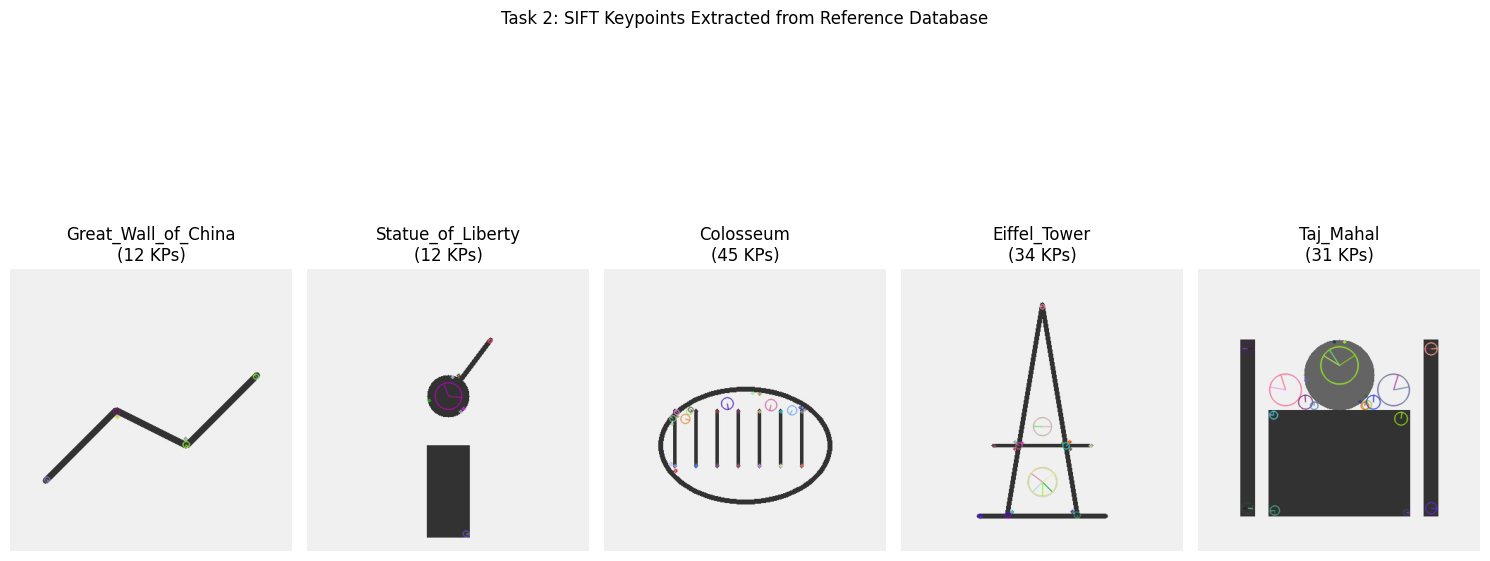

Task 2 Completed: Processed 5 landmark classes.


In [2]:
import cv2
import os
import glob
import matplotlib.pyplot as plt

# Initialize SIFT detector[cite: 1, 2]
sift = cv2.SIFT_create()

database_features = {}

plt.figure(figsize=(15, 8))
plot_idx = 1

for landmark in os.listdir('landmark_database'):
    landmark_path = os.path.join('landmark_database', landmark)
    if not os.path.isdir(landmark_path):
        continue

    database_features[landmark] = []
    image_files = glob.glob(os.path.join(landmark_path, '*.jpg'))

    for img_path in image_files:
        # 1. Load image and convert to grayscale[cite: 1, 4]
        img = cv2.imread(img_path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # 2 & 3. Detect keypoints and extract descriptors[cite: 1, 4]
        keypoints, descriptors = sift.detectAndCompute(gray, None)

        # 5. Store features[cite: 1]
        if descriptors is not None:
            database_features[landmark].append({
                'image_path': img_path,
                'image': img,
                'gray': gray,
                'keypoints': keypoints,
                'descriptors': descriptors
            })

        # 4. Display representative reference keypoint images[cite: 1]
        if img_path.endswith('_ref_1.jpg') and plot_idx <= 5:
            img_kp = cv2.drawKeypoints(gray, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
            plt.subplot(1, 5, plot_idx)
            plt.imshow(cv2.cvtColor(img_kp, cv2.COLOR_BGR2RGB))
            plt.title(f"{landmark}\n({len(keypoints)} KPs)")
            plt.axis('off')
            plot_idx += 1

plt.suptitle("Task 2: SIFT Keypoints Extracted from Reference Database")
plt.tight_layout()
plt.show()

print(f"Task 2 Completed: Processed {len(database_features)} landmark classes.")

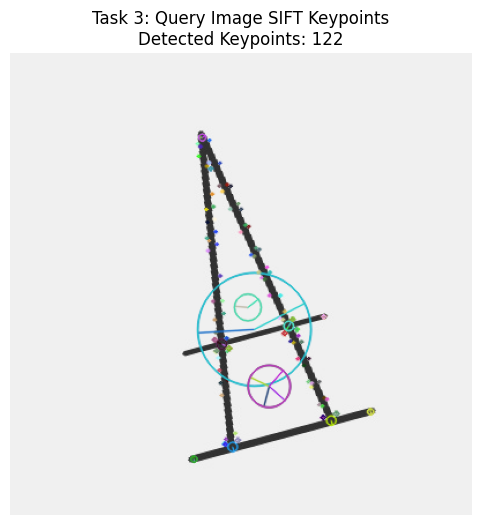

Task 3 Completed: Query image SIFT descriptors extracted.


In [3]:
# Generate or load a query image (e.g., Eiffel Tower test image)[cite: 1, 2]
query_img_raw = create_synthetic_landmark('Eiffel_Tower', variation=1)
cv2.imwrite('query_input.jpg', query_img_raw)

# 1. Load query image[cite: 2]
query_img = cv2.imread('query_input.jpg')

# 2. Convert to grayscale
query_gray = cv2.cvtColor(query_img, cv2.COLOR_BGR2GRAY)

# 3 & 4. Detect SIFT keypoints & extract descriptors
sift = cv2.SIFT_create()
query_kps, query_descs = sift.detectAndCompute(query_gray, None)

# 5. Display query image with keypoints[cite: 2, 4]
query_kp_img = cv2.drawKeypoints(query_gray, query_kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(query_kp_img, cv2.COLOR_BGR2RGB))
plt.title(f"Task 3: Query Image SIFT Keypoints\nDetected Keypoints: {len(query_kps)}")
plt.axis('off')
plt.show()

print("Task 3 Completed: Query image SIFT descriptors extracted.")

In [4]:
import cv2
import numpy as np

# Threshold config[cite: 2]
RATIO_THRESH = 0.75  # Lowe's ratio test threshold[cite: 2, 4]
MIN_MATCH_THRESHOLD = 15  # Minimum reliable matches required for acceptance[cite: 2]

bf = cv2.BFMatcher(cv2.NORM_L2) # Brute-Force Matcher Euclidean distance[cite: 2]
landmark_scores = {}
best_matches_dict = {}
best_ref_img_dict = {}

# Match query against all stored reference images[cite: 2]
for landmark, ref_data_list in database_features.items():
    total_good_matches = 0
    top_matches = []
    top_ref_entry = None

    for ref_entry in ref_data_list:
        ref_descs = ref_entry['descriptors']
        if ref_descs is None or query_descs is None:
            continue

        # K-NN matching (k=2)[cite: 2, 4]
        raw_matches = bf.knnMatch(query_descs, ref_descs, k=2)

        # Apply Lowe's ratio test[cite: 2, 4]
        good_matches = []
        for m_n in raw_matches:
            if len(m_n) == 2:
                m, n = m_n
                if m.distance < RATIO_THRESH * n.distance:
                    good_matches.append(m)

        if len(good_matches) > len(top_matches):
            top_matches = good_matches
            top_ref_entry = ref_entry

        total_good_matches += len(good_matches)

    landmark_scores[landmark] = len(top_matches)
    best_matches_dict[landmark] = top_matches
    best_ref_img_dict[landmark] = top_ref_entry

# Rank candidate landmarks[cite: 2, 4]
sorted_landmarks = sorted(landmark_scores.items(), key=lambda x: x[1], reverse=True)
predicted_landmark, top_match_count = sorted_landmarks[0]

# Threshold check decision[cite: 2]
if top_match_count >= MIN_MATCH_THRESHOLD:
    recognition_status = "Recognized"
else:
    recognition_status = "Rejected (Unknown/Insufficient Matches)"
    predicted_landmark = "Unknown Landmark"

print("--- Task 4: Match Summary ---")
for lm, score in sorted_landmarks:
    print(f"Landmark: {lm:<20} Reliable Matches: {score}")

print(f"\nPredicted Landmark: {predicted_landmark}")
print(f"Status: {recognition_status}")

--- Task 4: Match Summary ---
Landmark: Eiffel_Tower         Reliable Matches: 122
Landmark: Statue_of_Liberty    Reliable Matches: 27
Landmark: Great_Wall_of_China  Reliable Matches: 15
Landmark: Taj_Mahal            Reliable Matches: 13
Landmark: Colosseum            Reliable Matches: 10

Predicted Landmark: Eiffel_Tower
Status: Recognized


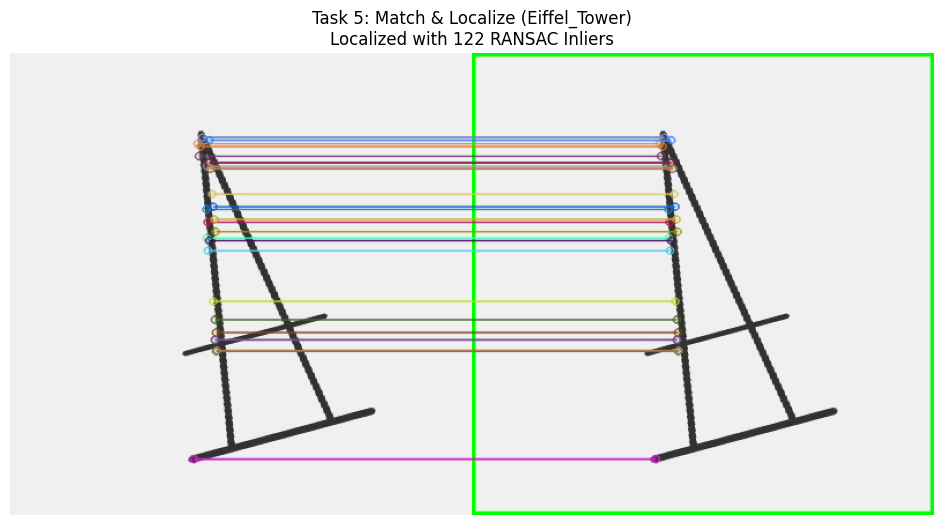

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

MIN_RANSAC_INLIERS = 10

if predicted_landmark != "Unknown Landmark":
    ref_entry = best_ref_img_dict[predicted_landmark]
    good_matches = best_matches_dict[predicted_landmark]

    # Extract match coordinates[cite: 2]
    src_pts = np.float32([ref_entry['keypoints'][m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([query_kps[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    # Estimate Homography using RANSAC[cite: 2, 4]
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    inliers_count = np.sum(mask) if mask is not None else 0

    query_output = query_img.copy()

    if H is not None and inliers_count >= MIN_RANSAC_INLIERS:
        # Project corner coordinates onto query image[cite: 2, 4]
        h, w = ref_entry['gray'].shape
        pts = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
        dst = cv2.perspectiveTransform(pts, H)

        # Draw bounding polygon[cite: 2, 4]
        query_output = cv2.polylines(query_output, [np.int32(dst)], True, (0, 255, 0), 4, cv2.LINE_AA)
        localization_msg = f"Localized with {inliers_count} RANSAC Inliers"
    else:
        localization_msg = "Geometric verification failed: Unreliable transformation."

    # Draw matched features
    match_img = cv2.drawMatches(
        ref_entry['image'], ref_entry['keypoints'],
        query_output, query_kps,
        good_matches[:30], None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(12, 6))
    plt.imshow(cv2.cvtColor(match_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Task 5: Match & Localize ({predicted_landmark})\n{localization_msg}")
    plt.axis('off')
    plt.show()

else:
    print("Task 5: Landmark unrecognized or rejected. Skipping localization.")

In [6]:
import time
import pandas as pd
import cv2
import numpy as np

# Helper test generator[cite: 2]
def get_test_condition_image(condition_name):
    base_img = create_synthetic_landmark('Eiffel_Tower', variation=0)

    if condition_name == "Original":
        return base_img
    elif condition_name == "Rotated (45 deg)":
        M = cv2.getRotationMatrix2D((200, 200), 45, 1.0)
        return cv2.warpAffine(base_img, M, (400, 400), borderValue=(240, 240, 240))
    elif condition_name == "Resized (50%)":
        h, w = base_img.shape[:2]
        resized = cv2.resize(base_img, (w // 2, h // 2))
        return cv2.resize(resized, (w, h))
    elif condition_name == "Reduced Brightness":
        return cv2.convertScaleAbs(base_img, alpha=0.4, beta=0)
    elif condition_name == "Different Viewpoint":
        return create_synthetic_landmark('Eiffel_Tower', variation=1)
    elif condition_name == "Unknown Landmark":
        # Generate an unknown shape (Circle pattern)[cite: 2]
        unk = np.ones((400, 400, 3), dtype=np.uint8) * 240
        cv2.circle(unk, (200, 200), 80, (20, 20, 20), 5)
        return unk

test_conditions = [
    "Original",
    "Rotated (45 deg)",
    "Resized (50%)",
    "Reduced Brightness",
    "Different Viewpoint",
    "Unknown Landmark"
]

evaluation_results = []

for condition in test_conditions:
    t_start = time.time()

    test_img = get_test_condition_image(condition)
    test_gray = cv2.cvtColor(test_img, cv2.COLOR_BGR2GRAY)

    # 1. Feature extraction[cite: 1, 2]
    kps, descs = sift.detectAndCompute(test_gray, None)
    num_kps = len(kps) if kps else 0

    best_lm = "Unknown Landmark"
    max_good_matches = 0

    if descs is not None:
        for lm, ref_list in database_features.items():
            for ref_entry in ref_list:
                ref_descs = ref_entry['descriptors']
                if ref_descs is None:
                    continue
                matches = bf.knnMatch(descs, ref_descs, k=2)
                good = [m for m_n in matches if len(m_n) == 2 for m, n in [m_n] if m.distance < 0.75 * n.distance]
                if len(good) > max_good_matches:
                    max_good_matches = len(good)
                    best_lm = lm

    # Decision rule[cite: 2]
    decision = "Recognized" if max_good_matches >= MIN_MATCH_THRESHOLD else "Rejected"
    if decision == "Rejected":
        best_lm = "Unknown / None"

    proc_time = round(time.time() - t_start, 4)

    evaluation_results.append({
        "Test Condition": condition,
        "Keypoints Detected": num_kps,
        "Reliable Matches": max_good_matches,
        "Predicted Landmark": best_lm,
        "Decision": decision,
        "Processing Time (s)": proc_time
    })

# Format and display output table[cite: 3]
results_df = pd.DataFrame(evaluation_results)
print("\n=== Task 6: Performance Evaluation Table ===")
display(results_df)


=== Task 6: Performance Evaluation Table ===


,Test Condition,Keypoints Detected,Reliable Matches,Predicted Landmark,Decision,Processing Time (s)
0,Original,33,33,Eiffel_Tower,Recognized,0.0366
1,Rotated (45 deg),110,42,Eiffel_Tower,Recognized,0.0353
2,Resized (50%),136,32,Eiffel_Tower,Recognized,0.0438
3,Reduced Brightness,28,28,Eiffel_Tower,Recognized,0.0291
4,Different Viewpoint,121,96,Eiffel_Tower,Recognized,0.0437
5,Unknown Landmark,10,2,Unknown / None,Rejected,0.0277
